# Day 08. Exercise 04
# Regression

## 0. Imports

In [82]:
import pandas as pd
from sklearn.model_selection import train_test_split

from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import numpy as np

import matplotlib.pyplot as plt

## 1. Preprocessing

1. Read the file [`checker_regression.csv`](https://drive.google.com/file/d/1L8auBzJEghWFewznhhFpcrqxW4GqcfRY/view?usp=sharing).
2. Fill the missing values in it with `0`.
3. Make a split of your dataset on train and test with parameters `test_size=0.2`.

In [83]:
df = pd.read_csv('../data/checker_regression.csv', usecols=['num_commits', 'pageviews', 'AVG(diff)'])

In [84]:
df.fillna(0, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   num_commits  77 non-null     int64  
 1   pageviews    77 non-null     float64
 2   AVG(diff)    77 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 1.9 KB


In [85]:
X = df[['num_commits', 'pageviews']]
y = df['AVG(diff)']

In [86]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=21)
X_train.head()

,num_commits,pageviews
11,20,89.0
42,65,10.0
8,20,89.0
1,62,28.0
7,20,89.0


## 2. Crossvalidation

1. Write a function `crossval` that takes as arguments: `n_splits` for `KFold()`, `X`, `y`, model instantiated class with the parameters of the model (keep in mind: `random_state=21`) and returns for a given model class a result like this:

```
train -  2696.4496895424836   |   test -  1589.9979527104958
train -  2660.957874001452   |   test -  2075.102636027137
train -  2847.315529246795   |   test -  320.911928168403
train -  2500.7691099659237   |   test -  4132.461382030178
train -  2643.927917295123   |   test -  2237.8140952197878
train -  2396.295678819444   |   test -  4509.650064742476
train -  2003.402267924976   |   test -  8403.491474908551
train -  2531.876094212613   |   test -  3135.944102735099
train -  2683.1795186023123   |   test -  1796.01426292594
train -  2537.1192483996338   |   test -  3439.29824116941
Average RMSE on crossval is 3164.0686140637476
```

2. Run the function for `LinearRegression`, `DecisionTreeRegressor`, `RandomForestRegressor`. You may choose the parameters by yourself, but find the good enough for you.

In [87]:
def crossval(n_splits, X, y, model):
    # init KFold
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=21)

    rmse_scores = []

    for i, (train_index, test_index) in enumerate(kf.split(X)): 
        # partition
        X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
        y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]

        model.fit(X_train_fold, y_train_fold)

        pred_train = model.predict(X_train_fold)
        pred_test = model.predict(X_test_fold)

        # среднеквадратическая ошибка
        mse_train = mean_squared_error(y_train_fold, pred_train)
        mse_test = mean_squared_error(y_test_fold, pred_test)
        
        rmse_train = np.sqrt(mse_train)
        rmse_test = np.sqrt(mse_test)

        rmse_scores.append(rmse_test)
        print(f"train -  {rmse_train:<20} |   test -  {rmse_test}")

    print(f"\nAverage RMSE on crossval is {np.mean(rmse_scores)}")

In [88]:
lr = LinearRegression()
crossval(10, X, y, lr)

train -  42.27291015233797    |   test -  70.43979397280242
train -  47.45726648237968    |   test -  30.65739401435404
train -  47.77854388604299    |   test -  27.137319378269105
train -  46.2441901620785     |   test -  44.123072052096376
train -  46.39355004742244    |   test -  42.420391728163665
train -  47.71541914802497    |   test -  28.273391654514054
train -  46.308918660456506   |   test -  45.67313727400561
train -  47.81194647242181    |   test -  20.57247658092342
train -  44.12915324532897    |   test -  63.14957718941947
train -  42.350893141368886   |   test -  74.15893330081012

Average RMSE on crossval is 44.66054871453583


In [89]:
dt = DecisionTreeRegressor(max_depth=5, random_state=21)
crossval(10, X, y, dt)

train -  14.24277944448863    |   test -  70.03725695021978
train -  15.13734501058241    |   test -  1.35676113640169
train -  15.142983685899988   |   test -  0.0
train -  12.618808138670614   |   test -  20.293964620053917
train -  10.30338704609208    |   test -  64.8447269337385
train -  12.661239429729635   |   test -  28.991378028648448
train -  14.893648339797917   |   test -  9.363849387256412
train -  12.80706042099373    |   test -  27.8418079930422
train -  4.462782011304528    |   test -  86.63649383194165
train -  11.939919454807958   |   test -  55.988817264969605

Average RMSE on crossval is 36.53550561462722


In [90]:
rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=21)
crossval(10, X, y, rf)

train -  12.777661106062592   |   test -  55.21884918830304
train -  14.944676960459738   |   test -  14.136950174002187
train -  15.145373082774338   |   test -  0.0
train -  14.781775951331486   |   test -  26.925919120802543
train -  12.998387321887547   |   test -  52.704000228872594
train -  15.162144682092565   |   test -  32.380540830875574
train -  16.39491297753858    |   test -  14.53373200141274
train -  14.98799883276986    |   test -  22.20654668271111
train -  14.09532647051205    |   test -  69.45674467575043
train -  15.00165717603498    |   test -  42.562647313312866

Average RMSE on crossval is 33.01259302160431


## 3. Predictions and evaluation

1. Make predictions for the test dataset using each of the three models with the finalized parameters.
2. Draw a plot for each of the models where the `x-axis` is the actual average difference and the `y-axis` is the prediction made by a model.
3. How would plot look like in the ideal case? Put the answer to the markdown cell in the end of the section.

In [91]:
models = [
    ('Linear Regression', lr),
    ('Decision Tree', dt),
    ('Random Forest', rf)
]

In [92]:
plt.figure(figsize=(18, 5))

<Figure size 1800x500 with 0 Axes>

<Figure size 1800x500 with 0 Axes>

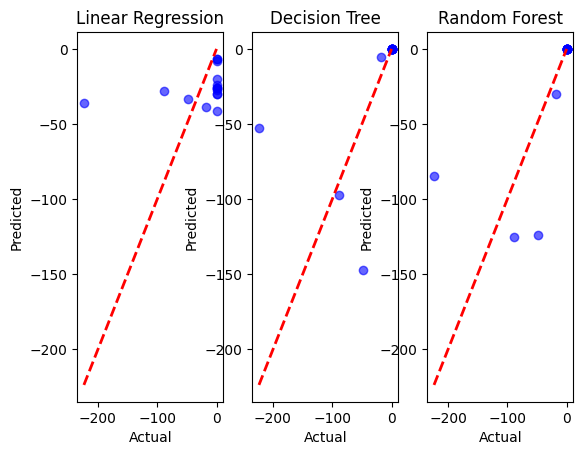

In [93]:
for i, (name, model) in enumerate(models):
    model.fit(X_train, y_train)

    preds = model.predict(X_test)

    ax = plt.subplot(1, 3, i+1)
    ax.scatter(y_test, preds, color='blue', alpha=0.6)
    
    # диагональ определяющая идеальные значения от мин до макс
    min_val = min(y_test.min(), preds.min())
    max_val = max(y_test.max(), preds.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2)
    
    ax.set_title(name)
    ax.set_xlabel('Actual')
    ax.set_ylabel('Predicted')

in the ideal case dots would lie exactly on the red diagonal